# 08 — Noise exposure and CHD prevalence in Ohio counties (secondary outcome)

**Question:** Is the share of residents exposed to transportation noise associated with county coronary heart disease prevalence?

**Data:** `data/processed/analysis_oh_county.csv` (from notebook 07). Outcome: CDC PLACES 2025 age-adjusted CHD prevalence (% of adults, mostly 2023 BRFSS).

**Analysis plan (fixed before fitting):**
| Element | Choice |
|---|---|
| Outcome | log(age-adjusted CHD prevalence) |
| Exposure | % residents ≥50 dBA (building-weighted); secondary: ≥45, ≥55 dBA |
| Covariates | % urban, % poverty, % non-Hispanic Black, smoking, PM2.5 (same as mortality) |
| Model | Linear regression with HC3 robust standard errors |
| Effect measure | Prevalence ratio per 5 percentage points (per IQR to compare thresholds) |
| Sensitivity | Weighted by county population; unadjusted |

**Caveat:** PLACES estimates are model-based and partly derived from demographics, and the smoking covariate comes from the same system, so associations may partly reflect the modeling rather than true county differences.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

PROCESSED = Path("../data/processed")
df = pd.read_csv(PROCESSED / "analysis_oh_county.csv", dtype={"county_fips": str})
assert len(df) == 88

# Same rescaling as notebook 07
for t in [45, 50, 55]:
    df[f"noise_ge{t}_5pp"] = df[f"noise_ge{t}"] * 100 / 5
for c in ["pct_urban", "pct_poverty", "pct_black_nh", "pct_smoking"]:
    df[f"{c}_pp"] = df[c] * 100
COVARS = "pct_urban_pp + pct_poverty_pp + pct_black_nh_pp + pct_smoking_pp + pm25"

df["log_chd"] = np.log(df["CHD"])
df["CHD"].describe().round(2)

count    88.00
mean      6.17
std       0.62
min       4.40
25%       5.70
50%       6.20
75%       6.60
max       7.70
Name: CHD, dtype: float64

In [3]:
def pr_table(res, term):
    """Prevalence ratio for one term, with 95% CI and p-value."""
    ci = res.conf_int().loc[term]
    return pd.Series({"PR": np.exp(res.params[term]),
                      "CI_low": np.exp(ci[0]), "CI_high": np.exp(ci[1]),
                      "p": res.pvalues[term]})

specs = {
    "Primary (>=50 dBA)":      (f"log_chd ~ noise_ge50_5pp + {COVARS}", "noise_ge50_5pp", None),
    "Unadjusted (>=50 dBA)":   ("log_chd ~ noise_ge50_5pp",             "noise_ge50_5pp", None),
    "Secondary: >=45 dBA":     (f"log_chd ~ noise_ge45_5pp + {COVARS}", "noise_ge45_5pp", None),
    "Secondary: >=55 dBA":     (f"log_chd ~ noise_ge55_5pp + {COVARS}", "noise_ge55_5pp", None),
    "Sens: population-weighted": (f"log_chd ~ noise_ge50_5pp + {COVARS}", "noise_ge50_5pp", "pop_wonder"),
}

rows, fits = [], {}
for name, (f, term, w) in specs.items():
    if w is None:
        res = smf.ols(f, data=df).fit(cov_type="HC3")
    else:
        res = smf.wls(f, data=df, weights=df[w]).fit(cov_type="HC3")
    fits[name] = res
    rows.append(pr_table(res, term).rename(name))

chd_results = pd.DataFrame(rows).round(3)
chd_results.to_csv("../outputs/ols_results_chd.csv")
chd_results

,PR,CI_low,CI_high,p
Primary (>=50 dBA),1.002,0.998,1.005,0.304
Unadjusted (>=50 dBA),0.992,0.973,1.012,0.433
Secondary: >=45 dBA,1.001,0.999,1.002,0.223
Secondary: >=55 dBA,1.003,0.989,1.018,0.642
Sens: population-weighted,1.001,0.991,1.011,0.867


R-squared: 0.975


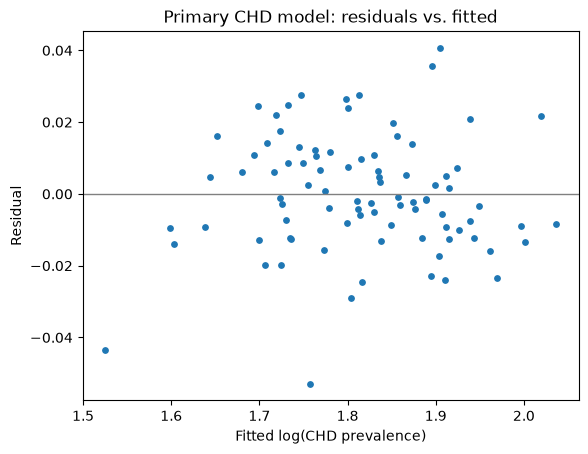

In [4]:
primary = fits["Primary (>=50 dBA)"]
print(f"R-squared: {primary.rsquared:.3f}")

import matplotlib.pyplot as plt
plt.scatter(primary.fittedvalues, primary.resid, s=15)
plt.axhline(0, color="gray", lw=1)
plt.xlabel("Fitted log(CHD prevalence)")
plt.ylabel("Residual")
plt.title("Primary CHD model: residuals vs. fitted")
plt.show()

## Interpretation

### Findings
- CHD prevalence showed no association with noise exposure: **PR 1.002 per 5 percentage points at ≥50 dBA (95% CI 0.998–1.005, p = 0.30)**. Estimates were similar at ≥45 dBA (1.001) and ≥55 dBA (1.003), unadjusted (0.992), and with population weighting (1.001).
- Residuals showed no pattern against fitted values.

### Why this result should be interpreted cautiously
- The model explains **97.5%** of county variation in CHD prevalence (R² = 0.975), far higher than typical for county health data. PLACES prevalence is model-based, estimated partly from demographic inputs that overlap with the covariates, and the smoking covariate comes from the same system.
- Noise is not an input to the PLACES model, so local variation related to noise can only appear in the small residual (2.5%). The narrow confidence interval reflects this artificially small residual variation, not strong evidence of no association.
- **Conclusion:** the null result likely reflects the limits of model-based prevalence data for studying exposures they were not modeled from, rather than evidence that noise is unrelated to CHD.

### Comparison with mortality (notebook 07)
- CVD mortality showed a positive but imprecise association (RR 1.019, 95% CI 0.998–1.041); CHD prevalence showed none.
- Possible explanations: observed death counts can capture local differences that modeled prevalence cannot; the outcomes differ (all circulatory deaths vs. diagnosed CHD); and the difference may be due to chance, since the mortality interval includes 1.
- The mortality analysis, based on observed counts, is the more informative of the two.

### Output
`outputs/ols_results_chd.csv`